
## Análisis de amenazas de ciberseguridad
 *Derly Viviana Benitez*,  *Juan*,   *Lina Marcela Lasso*


**Pregunta central:** ¿Cómo podemos usar la ciencia de datos para identificar patrones asociados a ataques informáticos y anticipar posibles amenazas?


# PARTE 1 — Datase
## Justificación del dataset

Elegimos el dataset **UNSW-NB15** porque reúne tráfico de red real mezclado con ataques modernos (DoS, Exploits, Reconnaissance, etc.).  
Nos permite estudiar, con datos concretos, la diferencia entre actividad normal y maliciosa.  
Se relaciona con la carrera porque une ciencia de datos y ciberseguridad: convertir registros de red en información útil para detectar amenazas.  

Fuente odataset: [UNSW Canberra — UNSW-NB15](https://research.unsw.edu.au/projects/unsw-nb15-dataset).

## Librerías y carpetas

cargamos las librerías del proyecto y creamos carpetas de salida.  
Para que el notebook pueda correr completo y guardar CSV y gráficas de forma ordenada.

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

os.makedirs("data", exist_ok=True)
os.makedirs("img", exist_ok=True)

print("=" * 65)
print("ANÁLISIS DE AMENAZAS DE CIBERSEGURIDAD | UNSW-NB15")
print("=" * 65)

ANÁLISIS DE AMENAZAS DE CIBERSEGURIDAD | UNSW-NB15


##  Carga de datos

Descargamos el training set de UNSW-NB15.  
Ya que, necesitamos los datos en memoria para explorar, limpiar y modelar.

In [5]:
URL_DATOS = (
    "https://raw.githubusercontent.com/stijnhuysman/DissertationData/main/"
    "UNSW_NB15_training-set.csv"
)

df = pd.read_csv(URL_DATOS)

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
print("\nPrimeras 5 filas:")
display(df.head())
print("\nNombres de columnas:")
print(list(df.columns))

Filas: 82,332 | Columnas: 45

Primeras 5 filas:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0



Nombres de columnas:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


Documentación de variables
Tabla con cada columna, su tipo y su significado.  

In [6]:
significado = {
    "id": "Identificador de la fila",
    "dur": "Duración de la conexión (segundos)",
    "proto": "Protocolo de red (tcp, udp, icmp...)",
    "service": "Servicio detectado (http, dns, ftp...) o '-' si no aplica",
    "state": "Estado de la conexión (FIN, INT, CON...)",
    "spkts": "Paquetes enviados por el origen",
    "dpkts": "Paquetes enviados por el destino",
    "sbytes": "Bytes enviados por el origen",
    "dbytes": "Bytes enviados por el destino",
    "rate": "Tasa de paquetes por segundo",
    "sttl": "TTL (tiempo de vida) en paquetes del origen",
    "dttl": "TTL en paquetes del destino",
    "sload": "Carga de bits/s desde el origen",
    "dload": "Carga de bits/s desde el destino",
    "sloss": "Paquetes perdidos del origen",
    "dloss": "Paquetes perdidos del destino",
    "sinpkt": "Intervalo promedio entre paquetes del origen",
    "dinpkt": "Intervalo promedio entre paquetes del destino",
    "sjit": "Jitter (variación de retardo) del origen",
    "djit": "Jitter del destino",
    "swin": "Ventana TCP del origen",
    "stcpb": "Número de secuencia TCP del origen",
    "dtcpb": "Número de secuencia TCP del destino",
    "dwin": "Ventana TCP del destino",
    "tcprtt": "Tiempo de ida y vuelta TCP (RTT)",
    "synack": "Tiempo entre SYN y SYN-ACK",
    "ackdat": "Tiempo entre SYN-ACK y ACK",
    "smean": "Tamaño medio de paquetes del origen",
    "dmean": "Tamaño medio de paquetes del destino",
    "trans_depth": "Profundidad de transacciones HTTP",
    "response_body_len": "Tamaño del cuerpo de respuesta HTTP",
    "ct_srv_src": "Conexiones al mismo servicio desde la misma IP origen",
    "ct_state_ttl": "Conteo según estado y TTL",
    "ct_dst_ltm": "Conexiones a la misma IP destino en ventana corta",
    "ct_src_dport_ltm": "Conexiones origen–puerto destino en ventana corta",
    "ct_dst_sport_ltm": "Conexiones destino–puerto origen en ventana corta",
    "ct_dst_src_ltm": "Conexiones entre el mismo par origen-destino",
    "is_ftp_login": "1 si hubo login FTP, 0 si no",
    "ct_ftp_cmd": "Comandos FTP en el flujo",
    "ct_flw_http_mthd": "Métodos HTTP en el flujo",
    "ct_src_ltm": "Conexiones desde la misma IP origen en ventana corta",
    "ct_srv_dst": "Conexiones al mismo servicio hacia la misma IP destino",
    "is_sm_ips_ports": "1 si origen y destino usan misma IP/puerto",
    "attack_cat": "Categoría del ataque (o Normal)",
    "label": "Variable objetivo: 0 = normal, 1 = ataque",
}

doc = pd.DataFrame({
    "variable": df.columns,
    "tipo_pandas": [str(df[c].dtype) for c in df.columns],
    "significado": [significado.get(c, "(revisar documentación oficial)") for c in df.columns],
})

print("Fuente: UNSW Canberra Cyber Range Lab (UNSW-NB15 training set)")
print(f"Registros: {len(df):,} | Variables: {df.shape[1]}")
display(doc)

print("\nCómo interpretarlo:")
print("- 'object' = texto/categoría; 'int64'/'float64' = números.")
print("- 'label' es la etiqueta que usaremos para predecir ataque vs normal.")

Fuente: UNSW Canberra Cyber Range Lab (UNSW-NB15 training set)
Registros: 82,332 | Variables: 45


,variable,tipo_pandas,significado
0,id,int64,Identificador de la fila
1,dur,float64,Duración de la conexión (segundos)
2,proto,object,"Protocolo de red (tcp, udp, icmp...)"
3,service,object,"Servicio detectado (http, dns, ftp...) o '-' s..."
4,state,object,"Estado de la conexión (FIN, INT, CON...)"
5,spkts,int64,Paquetes enviados por el origen
6,dpkts,int64,Paquetes enviados por el destino
7,sbytes,int64,Bytes enviados por el origen
8,dbytes,int64,Bytes enviados por el destino
9,rate,float64,Tasa de paquetes por segundo



Cómo interpretarlo:
- 'object' = texto/categoría; 'int64'/'float64' = números.
- 'label' es la etiqueta que usaremos para predecir ataque vs normal.


##  Exploración inicial

Revisamos tipos, nulos, duplicados y distribución normal/ataque.  
porque antes de limpiar hay que ver qué problemas hay.

In [ ]:
print("=== Tipos de datos ===")
display(df.dtypes.value_counts().rename("cantidad"))

print("\n=== Valores nulos (solo si hay) ===")
nulos = df.isna().sum()
nulos = nulos[nulos > 0]
print("No hay valores nulos (NaN)." if len(nulos) == 0 else nulos.sort_values(ascending=False))

print("\n=== Duplicados ===")
print(f"Filas duplicadas exactas: {df.duplicated().sum():,}")

print("\n=== Distribución de label ===")
display(df["label"].value_counts().rename(index={0: "Normal (0)", 1: "Ataque (1)"}))
display((df["label"].value_counts(normalize=True) * 100).round(2).rename(
    index={0: "Normal %", 1: "Ataque %"}
))

print("\n=== Categorías de ataque ===")
display(df["attack_cat"].value_counts())

print("\n=== service (el '-' = sin servicio) ===")
display(df["service"].value_counts().head(10))

cols_clave = [c for c in ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload"] if c in df.columns]
print("\n=== Resumen numérico de variables clave ===")
display(df[cols_clave].describe().T)

print("\nCómo interpretarlo:")
print("- Si una clase domina (más ataques o más normal), el modelo puede sesgarse.")
print("- El '-' en service no es error: significa 'sin servicio identificado'.")
print("- Valores muy altos en sbytes/rate pueden ser tráfico intenso o indicios de ataque.")

=== Tipos de datos ===


,cantidad
int64,30
float64,11
object,4



=== Valores nulos (solo si hay) ===
No hay valores nulos (NaN).

=== Duplicados ===
Filas duplicadas exactas: 0

=== Distribución de label ===


,count
label,
Ataque (1),45332
Normal (0),37000


,proportion
label,
Ataque %,55.06
Normal %,44.94



=== Categorías de ataque ===


... (2 outputs left out)

,count
service,
-,47153
dns,21367
http,8287
smtp,1851
ftp,1552
ftp-data,1396
pop3,423
ssh,204
ssl,30



=== Resumen numérico de variables clave ===


,count,mean,std,min,25%,50%,75%,max
dur,82332.0,1.006756e+00,4.710444e+00,0.0,0.000008,0.014138,7.193603e-01,5.999999e+01
spkts,82332.0,1.866647e+01,1.339164e+02,1.0,2.000000,6.000000,1.200000e+01,1.064600e+04
dpkts,82332.0,1.754594e+01,1.155741e+02,0.0,0.000000,2.000000,1.000000e+01,1.101800e+04
sbytes,82332.0,7.993908e+03,1.716423e+05,24.0,114.000000,534.000000,1.280000e+03,1.435577e+07
dbytes,82332.0,1.323379e+04,1.514715e+05,0.0,0.000000,178.000000,9.560000e+02,1.465753e+07
rate,82332.0,8.241089e+04,1.486204e+05,0.0,28.606114,2650.176667,1.111111e+05,1.000000e+06
sload,82332.0,6.454902e+07,1.798618e+08,0.0,11202.466797,577003.218750,6.514286e+07,5.268000e+09
dload,82332.0,6.305470e+05,2.393001e+06,0.0,0.000000,2112.951416,1.585808e+04,2.082111e+07



Cómo interpretarlo:
- Si una clase domina (más ataques o más normal), el modelo puede sesgarse.
- El '-' en service no es error: significa 'sin servicio identificado'.
- Valores muy altos en sbytes/rate pueden ser tráfico intenso o indicios de ataque.


## Limpieza de datos

Quitamos columnas inútiles, unificamos textos, tratamos `-` en service y eliminamos duplicados.  
Datos limpios = estadísticas y modelos más confiables.

In [ ]:
filas_antes, cols_antes = df.shape
df_clean = df.copy()

if "id" in df_clean.columns:
    df_clean = df_clean.drop(columns=["id"])
    print("Decisión: eliminamos 'id' (no describe el comportamiento del tráfico).")

for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()
print("Decisión: quitamos espacios en textos.")

if "service" in df_clean.columns:
    df_clean["service"] = df_clean["service"].replace({"-": "none", "nan": "none"})
    print("Decisión: '-' en service → 'none'.")

for col in ["proto", "state", "service", "attack_cat"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].str.lower()
print("Decisión: categorías a minúsculas.")

df_clean["label"] = pd.to_numeric(df_clean["label"], errors="coerce")
n_label_malo = df_clean["label"].isna().sum()
df_clean = df_clean.dropna(subset=["label"])
df_clean["label"] = df_clean["label"].astype(int)
print(f"Decisión: label como entero 0/1. Filas inválidas eliminadas: {n_label_malo}")

if "attack_cat" in df_clean.columns:
    incoherentes = (
        ((df_clean["label"] == 0) & (df_clean["attack_cat"] != "normal"))
        | ((df_clean["label"] == 1) & (df_clean["attack_cat"] == "normal"))
    ).sum()
    print(f"Filas con posible incoherencia label/attack_cat: {incoherentes}")

dup_antes = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Decisión: eliminamos {dup_antes:,} duplicados exactos.")

nulos_restantes = df_clean.isna().sum().sum()
if nulos_restantes > 0:
    for col in df_clean.columns:
        if df_clean[col].isna().any():
            if pd.api.types.is_numeric_dtype(df_clean[col]):
                df_clean[col] = df_clean[col].fillna(df_clean[col].median())
            else:
                moda = df_clean[col].mode()
                df_clean[col] = df_clean[col].fillna(moda.iloc[0] if len(moda) else "desconocido")
    print(f"Decisión: rellenamos {nulos_restantes} nulos (mediana/moda).")
else:
    print("No quedaron nulos que rellenar.")

filas_despues, cols_despues = df_clean.shape
print(f"\nAntes: {filas_antes:,} x {cols_antes} | Después: {filas_despues:,} x {cols_despues}")

Decisión: eliminamos 'id' (no describe el comportamiento del tráfico).
Decisión: quitamos espacios en textos.
Decisión: '-' en service → 'none'.
Decisión: categorías a minúsculas.
Decisión: label como entero 0/1. Filas inválidas eliminadas: 0
Filas con posible incoherencia label/attack_cat: 0
Decisión: eliminamos 26,387 duplicados exactos.
No quedaron nulos que rellenar.

Antes: 82,332 x 45 | Después: 55,945 x 44


##  Resumen depurado y guardado del CSV

Comparamos antes/después y guardamos el CSV limpio.  

In [ ]:
resumen = pd.DataFrame({
    "métrica": ["Filas", "Columnas", "Nulos totales", "Duplicados", "% Normal", "% Ataque"],
    "antes": [
        filas_antes,
        cols_antes,
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        round((df["label"] == 0).mean() * 100, 2),
        round((df["label"] == 1).mean() * 100, 2),
    ],
    "después": [
        filas_despues,
        cols_despues,
        int(df_clean.isna().sum().sum()),
        int(df_clean.duplicated().sum()),
        round((df_clean["label"] == 0).mean() * 100, 2),
        round((df_clean["label"] == 1).mean() * 100, 2),
    ],
})

print("=== Comparación antes vs después ===")
display(resumen)
display(df_clean.head())

ruta_csv = "data/UNSW_NB15_limpio.csv"
df_clean.to_csv(ruta_csv, index=False)
print(f"\nCSV limpio guardado en: {ruta_csv}")
# from google.colab import files
# files.download(ruta_csv)

print("\nCómo interpretarlo:")
print("- Si bajaron filas: duplicados o etiquetas inválidas.")
print("- Si bajó una columna: normalmente fue 'id'.")
print("- data/UNSW_NB15_limpio.csv es la base para estadística y el modelo.")

=== Comparación antes vs después ===


,métrica,antes,después
0,Filas,82332.00,55945.00
1,Columnas,45.00,44.00
2,Nulos totales,0.00,0.00
3,Duplicados,0.00,0.00
4,% Normal,44.94,61.14
5,% Ataque,55.06,38.86


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.000011,udp,none,int,2,0,496,0,90909.0902,254,...,1,2,0,0,0,1,2,0,normal,0
1,0.000008,udp,none,int,2,0,1762,0,125000.0003,254,...,1,2,0,0,0,1,2,0,normal,0
2,0.000005,udp,none,int,2,0,1068,0,200000.0051,254,...,1,3,0,0,0,1,3,0,normal,0
3,0.000006,udp,none,int,2,0,900,0,166666.6608,254,...,1,3,0,0,0,2,3,0,normal,0
4,0.000010,udp,none,int,2,0,2126,0,100000.0025,254,...,1,3,0,0,0,2,3,0,normal,0



CSV limpio guardado en: data/UNSW_NB15_limpio.csv

Cómo interpretarlo:
- Si bajaron filas: duplicados o etiquetas inválidas.
- Si bajó una columna: normalmente fue 'id'.
- data/UNSW_NB15_limpio.csv es la base para estadística y el modelo.


# PARTE 2 — Estadística descriptiva y gráficas

##  Media, mediana y moda

Calculamos media (promedio), mediana (valor del medio) y moda (valor más frecuente) en variables clave.  
Porque resumen cómo se comporta el tráfico y si hay valores extremos que “jalan” el promedio.

In [ ]:
# Variables numéricas clave para el análisis
vars_clave = [c for c in ["dur", "spkts", "dpkts", "sbytes", "dbytes", "rate", "sload", "dload", "sttl", "smean", "dmean"] if c in df_clean.columns]

filas_stats = []
for col in vars_clave:
    serie = df_clean[col]
    moda = serie.mode()
    filas_stats.append({
        "variable": col,
        "media": round(serie.mean(), 4),
        "mediana": round(serie.median(), 4),
        "moda": round(moda.iloc[0], 4) if len(moda) else np.nan,
    })

tabla_mmm = pd.DataFrame(filas_stats)
display(tabla_mmm)

print("\nCómo interpretarlo:")
print("- Si media >> mediana, hay valores muy altos (colas largas): típico en bytes o rate.")
print("- La moda muestra el valor más común; útil en variables como sttl.")
print("- En ciberseguridad, promedios altos de sbytes/rate pueden asociarse a tráficos intensos o ataques.")

,variable,media,mediana,moda
0,dur,1.032800e+00,0.3510,0.000000e+00
1,spkts,2.511470e+01,10.0000,1.000000e+01
2,dpkts,2.505230e+01,8.0000,0.000000e+00
3,sbytes,1.094235e+04,858.0000,1.140000e+02
4,dbytes,1.915921e+04,354.0000,0.000000e+00
5,rate,4.134040e+04,72.8504,1.111111e+05
6,sload,4.793749e+07,48097.3086,5.066666e+07
7,dload,9.240539e+05,5157.8140,0.000000e+00
8,sttl,1.544837e+02,254.0000,2.540000e+02
9,smean,1.664618e+02,79.0000,5.700000e+01



Cómo interpretarlo:
- Si media >> mediana, hay valores muy altos (colas largas): típico en bytes o rate.
- La moda muestra el valor más común; útil en variables como sttl.
- En ciberseguridad, promedios altos de sbytes/rate pueden asociarse a tráficos intensos o ataques.


## Rango, varianza y desviación estándar

Medimos dispersión: rango (máx−mín), varianza y desviación estándar (qué tan lejos están los datos del promedio).  
Porque mucha dispersión sugiere comportamientos muy distintos entre conexiones (normal vs ataque).

In [ ]:
filas_disp = []
for col in vars_clave:
    serie = df_clean[col]
    filas_disp.append({
        "variable": col,
        "mín": round(serie.min(), 4),
        "máx": round(serie.max(), 4),
        "rango": round(serie.max() - serie.min(), 4),
        "varianza": round(serie.var(), 4),
        "desv_estándar": round(serie.std(), 4),
    })

tabla_disp = pd.DataFrame(filas_disp)
display(tabla_disp)

print("\nCómo interpretarlo:")
print("- Rango grande = hay conexiones muy distintas (casi vacías vs muy pesadas).")
print("- Desviación alta = los valores se alejan mucho del promedio.")
print("- En seguridad, alta dispersión en rate/sbytes puede indicar picos anómalos dignos de alerta.")

,variable,mín,máx,rango,varianza,desv_estándar
0,dur,0.0,6.000000e+01,6.000000e+01,1.672820e+01,4.090000e+00
1,spkts,1.0,1.064600e+04,1.064500e+04,2.506513e+04,1.583197e+02
2,dpkts,0.0,1.101800e+04,1.101800e+04,1.938696e+04,1.392371e+02
3,sbytes,24.0,1.435577e+07,1.435575e+07,4.141414e+10,2.035046e+05
4,dbytes,0.0,1.465753e+07,1.465753e+07,3.358868e+10,1.832721e+05
5,rate,0.0,1.000000e+06,1.000000e+06,1.379459e+10,1.174504e+05
6,sload,0.0,5.268000e+09,5.268000e+09,3.814969e+16,1.953194e+08
7,dload,0.0,2.082111e+07,2.082111e+07,8.142924e+12,2.853581e+06
8,sttl,0.0,2.550000e+02,2.550000e+02,1.135690e+04,1.065687e+02
9,smean,24.0,1.504000e+03,1.480000e+03,5.722917e+04,2.392262e+02



Cómo interpretarlo:
- Rango grande = hay conexiones muy distintas (casi vacías vs muy pesadas).
- Desviación alta = los valores se alejan mucho del promedio.
- En seguridad, alta dispersión en rate/sbytes puede indicar picos anómalos dignos de alerta.


##  Comparación: actividad normal vs maliciosa

Comparamos promedios de variables clave entre `label=0` (normal) y `label=1` (ataque).  
Nos ayuda a buscar diferencias que ayuden a distinguir amenazas.

In [ ]:
df_clean["tipo_trafico"] = df_clean["label"].map({0: "Normal", 1: "Malicioso"})

comparacion = (
    df_clean.groupby("tipo_trafico")[vars_clave]
    .mean()
    .T
    .rename(columns={"Normal": "media_normal", "Malicioso": "media_malicioso"})
)
comparacion["diferencia"] = comparacion["media_malicioso"] - comparacion["media_normal"]
display(comparacion.round(4))

print("\nCómo interpretarlo:")
print("- Si media_malicioso es claramente mayor/menor, esa variable ayuda a separar clases.")
print("- Ejemplo típico: sttl o rate suelen comportarse distinto en ataques.")
print("- Estas diferencias alimentan las hipótesis y el modelo predictivo.")

tipo_trafico,media_malicioso,media_normal,diferencia
dur,1.273700e+00,8.797000e-01,3.939000e-01
spkts,2.658180e+01,2.418240e+01,2.399400e+00
dpkts,2.164110e+01,2.722020e+01,-5.579100e+00
sbytes,2.132877e+04,4.341449e+03,1.698732e+04
dbytes,1.759172e+04,2.015540e+04,-2.563675e+03
rate,6.698345e+04,2.504342e+04,4.194003e+04
sload,6.528149e+07,3.691482e+07,2.836667e+07
dload,4.694897e+04,1.481482e+06,-1.434533e+06
sttl,2.063947e+02,1.214926e+02,8.490210e+01
smean,1.815369e+02,1.568811e+02,2.465580e+01



Cómo interpretarlo:
- Si media_malicioso es claramente mayor/menor, esa variable ayuda a separar clases.
- Ejemplo típico: sttl o rate suelen comportarse distinto en ataques.
- Estas diferencias alimentan las hipótesis y el modelo predictivo.


## Gráfica de barras: normal vs maliciosa

Contamos cuántos registros hay de cada tipo.  
Nos permite ver el balance de clases de un vistazo.

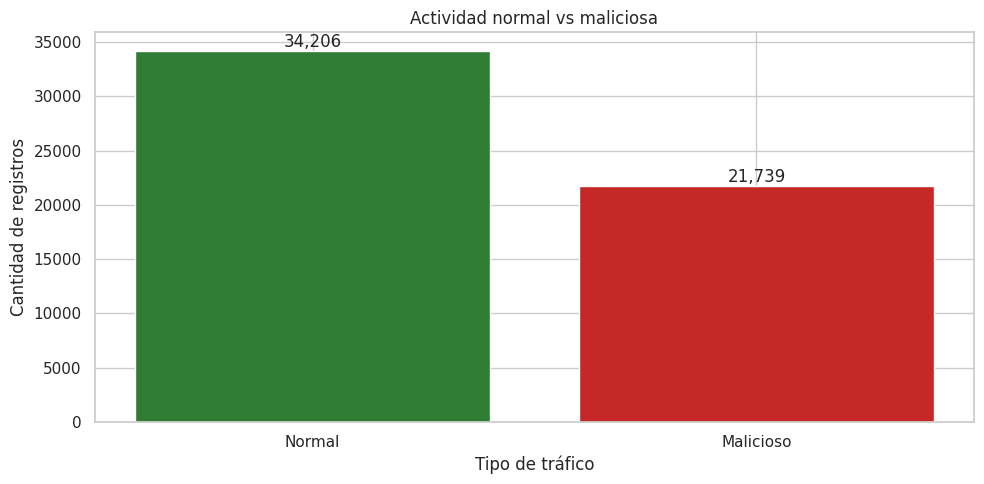

Cómo interpretarlo:
- La barra más alta es la clase mayoritaria.
- Un desbalance fuerte afecta accuracy: por eso también miramos recall de ataque.


In [ ]:
conteo = df_clean["tipo_trafico"].value_counts().reindex(["Normal", "Malicioso"])

fig, ax = plt.subplots()
barras = ax.bar(conteo.index, conteo.values, color=["#2E7D32", "#C62828"])
ax.set_title("Actividad normal vs maliciosa")
ax.set_xlabel("Tipo de tráfico")
ax.set_ylabel("Cantidad de registros")
for b, v in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig("img/barras_normal_vs_maliciosa.png", dpi=150, bbox_inches="tight")
plt.show()

print("Cómo interpretarlo:")
print("- La barra más alta es la clase mayoritaria.")
print("- Un desbalance fuerte afecta accuracy: por eso también miramos recall de ataque.")

## Histogramas de variables clave

Mostramos la distribución de algunas variables (separando normal y malicioso).  
Nos permite ver la forma de los datos y posibles diferencias entre clases.

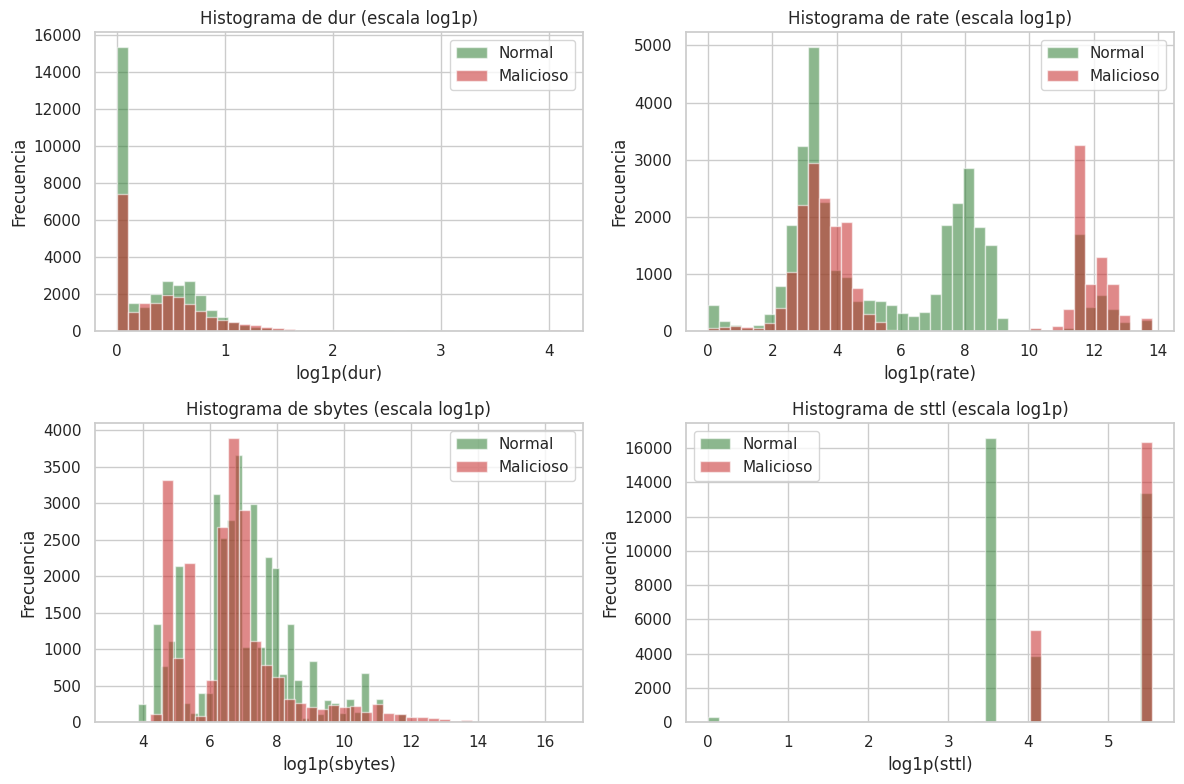

Cómo interpretarlo:
- Usamos log1p porque bytes/rate tienen colas muy largas; así se ve mejor la forma.
- Si las curvas verde y roja se separan, esa variable discrimina bien.


In [ ]:
vars_hist = [c for c in ["dur", "rate", "sbytes", "sttl"] if c in df_clean.columns]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for ax, col in zip(axes, vars_hist):
    # Usamos log1p para variables muy sesgadas (valores extremos)
    for nombre, color in [("Normal", "#2E7D32"), ("Malicioso", "#C62828")]:
        datos = np.log1p(df_clean.loc[df_clean["tipo_trafico"] == nombre, col].clip(lower=0))
        ax.hist(datos, bins=40, alpha=0.55, label=nombre, color=color)
    ax.set_title(f"Histograma de {col} (escala log1p)")
    ax.set_xlabel(f"log1p({col})")
    ax.set_ylabel("Frecuencia")
    ax.legend()

plt.tight_layout()
plt.savefig("img/histogramas_variables_clave.png", dpi=150, bbox_inches="tight")
plt.show()

print("Cómo interpretarlo:")
print("- Usamos log1p porque bytes/rate tienen colas muy largas; así se ve mejor la forma.")
print("- Si las curvas verde y roja se separan, esa variable discrimina bien.")

##  Outliers (método IQR) y boxplots

Detectamos valores atípicos con el rango intercuartílico (IQR) y los visualizamos con boxplots.  
Porque en seguridad, un outlier puede ser un pico de ataque… o un error de medición.

,variable,outliers,%_outliers,limite_inf,limite_sup
0,dur,3334,5.96,-1.371300e+00,2.288400e+00
1,rate,10928,19.53,-6.253808e+03,1.048829e+04
2,sbytes,7059,12.62,-1.877000e+03,4.419000e+03
3,dbytes,9366,16.74,-2.187000e+03,4.077000e+03
4,sload,11637,20.80,-2.030898e+06,3.407665e+06


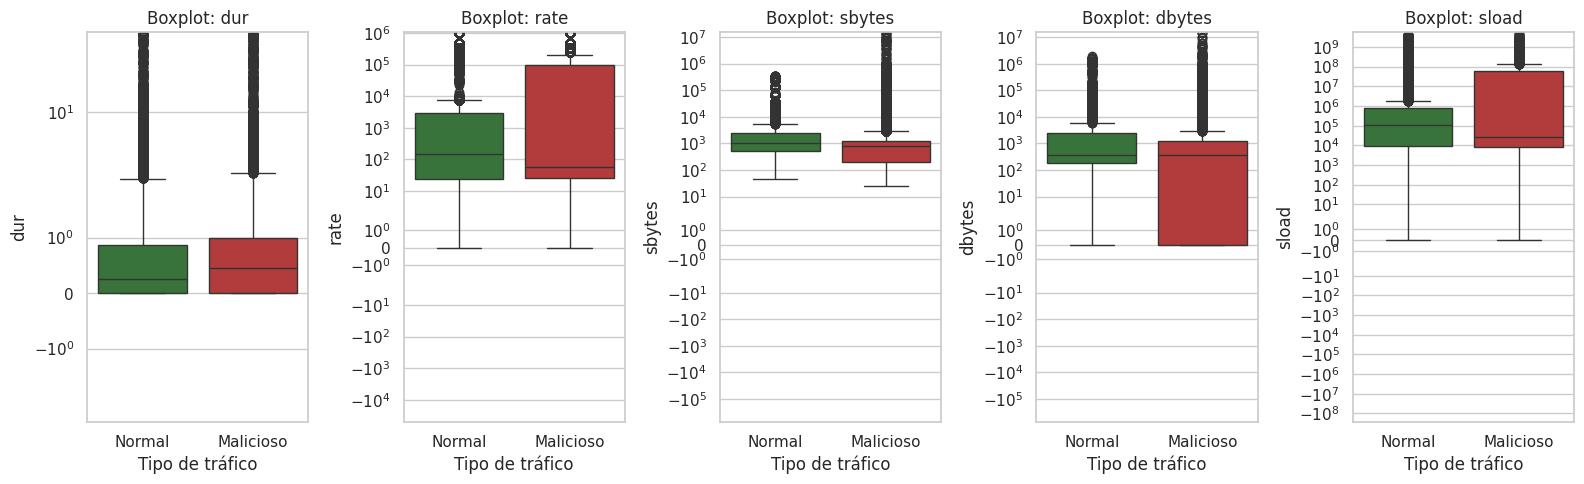

Cómo interpretarlo:
- IQR: valores fuera de [Q1-1.5·IQR, Q3+1.5·IQR] se consideran atípicos.
- En ciberseguridad, outliers de rate/sbytes pueden ser escaneos, DoS o transferencias anómalas.
- No los borramos automáticamente: a menudo son la señal del ataque.


In [ ]:
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (serie < lim_inf) | (serie > lim_sup)
    return int(mask.sum()), lim_inf, lim_sup

vars_out = [c for c in ["dur", "rate", "sbytes", "dbytes", "sload"] if c in df_clean.columns]
res_out = []
for col in vars_out:
    n_out, lo, hi = contar_outliers_iqr(df_clean[col])
    res_out.append({
        "variable": col,
        "outliers": n_out,
        "%_outliers": round(100 * n_out / len(df_clean), 2),
        "limite_inf": round(lo, 4),
        "limite_sup": round(hi, 4),
    })

display(pd.DataFrame(res_out))

fig, axes = plt.subplots(1, len(vars_out), figsize=(3.2 * len(vars_out), 5))
if len(vars_out) == 1:
    axes = [axes]

for ax, col in zip(axes, vars_out):
    sns.boxplot(
        data=df_clean,
        x="tipo_trafico",
        y=col,
        ax=ax,
        palette={"Normal": "#2E7D32", "Malicioso": "#C62828"},
        showfliers=True,
    )
    ax.set_title(f"Boxplot: {col}")
    ax.set_xlabel("Tipo de tráfico")
    ax.set_ylabel(col)
    # Escala log para leer mejor valores extremos
    if df_clean[col].max() > 0:
        ax.set_yscale("symlog")

plt.tight_layout()
plt.savefig("img/boxplots_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

print("Cómo interpretarlo:")
print("- IQR: valores fuera de [Q1-1.5·IQR, Q3+1.5·IQR] se consideran atípicos.")
print("- En ciberseguridad, outliers de rate/sbytes pueden ser escaneos, DoS o transferencias anómalas.")
print("- No los borramos automáticamente: a menudo son la señal del ataque.")

## Mapa de calor de correlaciones

Medimos qué tan relacionadas están las variables numéricas entre sí (y con `label`).  

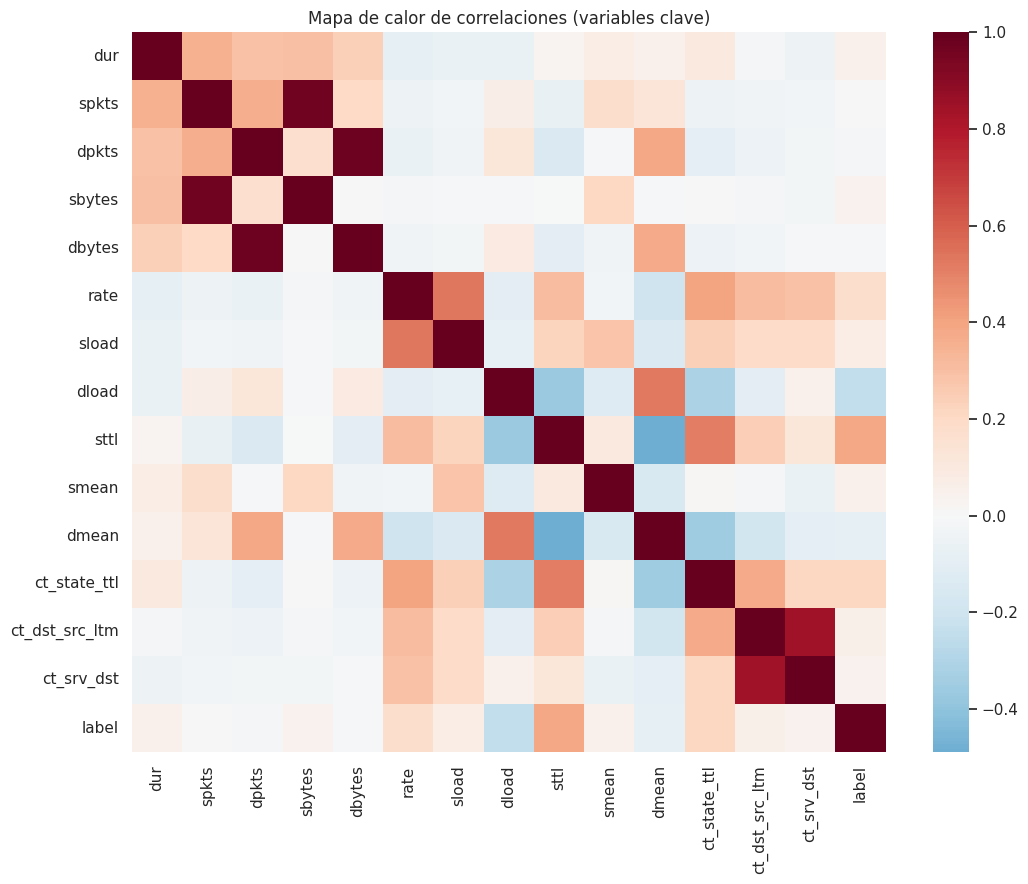

Correlación de cada variable con label (ataque):


,label
sttl,0.3883
dload,-0.2450
ct_state_ttl,0.2195
rate,0.1741
dmean,-0.0934
sload,0.0708
ct_dst_src_ltm,0.0605
smean,0.0502
dur,0.0469
ct_srv_dst,0.0411



Cómo interpretarlo:
- Correlación cerca de +1 o -1: relación fuerte (positiva o inversa).
- Cerca de 0: poca relación lineal.
- Las más correlacionadas con label suelen ser las más útiles para predecir ataques.


In [ ]:
# Tomamos variables numéricas + label (sin saturar el gráfico)
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
# Priorizamos variables clave + label
prefs = [c for c in vars_clave + ["ct_state_ttl", "ct_dst_src_ltm", "ct_srv_dst", "label"] if c in num_cols]
corr = df_clean[prefs].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=False, cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Mapa de calor de correlaciones (variables clave)")
plt.tight_layout()
plt.savefig("img/mapa_calor_correlaciones.png", dpi=150, bbox_inches="tight")
plt.show()

print("Correlación de cada variable con label (ataque):")
corr_label = corr["label"].drop("label").sort_values(key=abs, ascending=False)
display(corr_label.round(4))

print("\nCómo interpretarlo:")
print("- Correlación cerca de +1 o -1: relación fuerte (positiva o inversa).")
print("- Cerca de 0: poca relación lineal.")
print("- Las más correlacionadas con label suelen ser las más útiles para predecir ataques.")

##  Hipótesis o relaciones encontradas

Planteamos 2–3 hipótesis a partir de lo observado.

In [ ]:
print("Hipótesis basadas en la exploración:")
print()
print("H1. El tráfico malicioso presenta valores de sttl / rate distintos al tráfico normal,")
print("    por lo que esas variables ayudan a separar clases.")
print()
print("H2. Variables de volumen (sbytes, dbytes, sload) tienen muchos outliers;")
print("    en seguridad esos picos pueden asociarse a ataques de alto volumen (p. ej. DoS).")
print()
print("H3. Conteos de conexiones recientes (ct_*) se relacionan con label:")
print("    patrones de muchas conexiones en poco tiempo pueden indicar reconocimiento o abuso.")
print()
print("Cómo interpretarlo:")
print("- Son hipótesis de trabajo: el modelo de la Parte 3 las pondrá a prueba.")
print("- Si el recall de ataque es alto y esas variables salen importantes, se refuerzan.")

Hipótesis basadas en la exploración:

H1. El tráfico malicioso presenta valores de sttl / rate distintos al tráfico normal,
    por lo que esas variables ayudan a separar clases.

H2. Variables de volumen (sbytes, dbytes, sload) tienen muchos outliers;
    en seguridad esos picos pueden asociarse a ataques de alto volumen (p. ej. DoS).

H3. Conteos de conexiones recientes (ct_*) se relacionan con label:
    patrones de muchas conexiones en poco tiempo pueden indicar reconocimiento o abuso.

Cómo interpretarlo:
- Son hipótesis de trabajo: el modelo de la Parte 3 las pondrá a prueba.
- Si el recall de ataque es alto y esas variables salen importantes, se refuerzan.


# PARTE 3 — Modelo predictivo

Variable objetivo y preparación de datos

Definimos `label` (0=normal, 1=ataque), preparamos features numéricas y separamos entrenamiento/prueba.  
Porque el modelo aprende patrones en train y se evalúa en test (datos que no vio).

In [ ]:
# Variable objetivo
y = df_clean["label"].astype(int)

# Features: numéricas, sin filtrar label ni columnas de fuga de información
# attack_cat describe el tipo de ataque: no se usa como entrada (sería "hacer trampa")
cols_excluir = {"label", "attack_cat", "tipo_trafico"}
X = df_clean.drop(columns=[c for c in cols_excluir if c in df_clean.columns])
X = X.select_dtypes(include=[np.number]).copy()

print("Variable objetivo: label → 0 = Normal, 1 = Ataque")
print(f"Features numéricas usadas: {X.shape[1]}")
print(list(X.columns))

# Separación 80% train / 20% test (estratificada para mantener proporción de clases)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\nTrain: {X_train.shape[0]:,} filas | Test: {X_test.shape[0]:,} filas")
print("Proporción de ataques en train:", round(y_train.mean(), 4))
print("Proporción de ataques en test:", round(y_test.mean(), 4))

# Escalado: ayuda a la regresión logística (pone variables en escala comparable)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print("\nCómo interpretarlo:")
print("- stratify mantiene el % de ataques en train y test.")
print("- No usamos attack_cat como entrada: eso revelaría la respuesta.")
print("- StandardScaler no cambia el orden de importancia relativa para Random Forest.")

Variable objetivo: label → 0 = Normal, 1 = Ataque
Features numéricas usadas: 39
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']

Train: 44,756 filas | Test: 11,189 filas
Proporción de ataques en train: 0.3886
Proporción de ataques en test: 0.3886

Cómo interpretarlo:
- stratify mantiene el % de ataques en train y test.
- No usamos attack_cat como entrada: eso revelaría la respuesta.
- StandardScaler no cambia el orden de importancia relativa para Random Forest.


##  Entrenar modelos (regresión logística + Random Forest)

Entrenamos una regresión logística (modelo lineal interpretable) y un Random Forest para comparar.  
Porque ver si un modelo más flexible mejora la detección de ataques.

In [ ]:
# Regresión logística: estima la probabilidad de ataque
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_reg.fit(X_train_sc, y_train)
y_pred_lr = log_reg.predict(X_test_sc)

# Random Forest (opcional de comparación): conjunto de árboles
rf = RandomForestClassifier(
    n_estimators=150,
    max_depth=18,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)  # RF no necesita escalado
y_pred_rf = rf.predict(X_test)

print("Modelos entrenados: LogisticRegression y RandomForestClassifier")
print("class_weight='balanced' mitiga el desbalance entre normal y ataque.")

Modelos entrenados: LogisticRegression y RandomForestClassifier
class_weight='balanced' mitiga el desbalance entre normal y ataque.


##  Evaluación: accuracy, precisión, recall y matriz de confusión

Medimos qué tan bien clasifica cada modelo, con énfasis en el recall de ataque.  
Porque en ciberseguridad, un falso negativo (ataque no detectado) suele ser más grave que una falsa alarma.

In [ ]:
def metricas(nombre, y_true, y_pred):
    return {
        "modelo": nombre,
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "precision_ataque": round(precision_score(y_true, y_pred, pos_label=1), 4),
        "recall_ataque": round(recall_score(y_true, y_pred, pos_label=1), 4),
        "f1_ataque": round(f1_score(y_true, y_pred, pos_label=1), 4),
    }

tabla_metricas = pd.DataFrame([
    metricas("Regresión logística", y_test, y_pred_lr),
    metricas("Random Forest", y_test, y_pred_rf),
])
display(tabla_metricas)

print("\nReporte detallado — Regresión logística:")
print(classification_report(y_test, y_pred_lr, target_names=["Normal", "Ataque"]))

print("Reporte detallado — Random Forest:")
print(classification_report(y_test, y_pred_rf, target_names=["Normal", "Ataque"]))

print("Cómo interpretarlo:")
print("- Accuracy: % de aciertos totales.")
print("- Precisión de ataque: de las alertas, cuántas eran ataques de verdad.")
print("- Recall de ataque: de todos los ataques reales, cuántos detectamos.")
print("- En seguridad priorizamos recall de ataque: fallar un ataque cuesta más que una falsa alarma.")

,modelo,accuracy,precision_ataque,recall_ataque,f1_ataque
0,Regresión logística,0.8306,0.7316,0.8910,0.8035
1,Random Forest,0.9654,0.9620,0.9485,0.9552



Reporte detallado — Regresión logística:
              precision    recall  f1-score   support

      Normal       0.92      0.79      0.85      6841
      Ataque       0.73      0.89      0.80      4348

    accuracy                           0.83     11189
   macro avg       0.83      0.84      0.83     11189
weighted avg       0.85      0.83      0.83     11189

Reporte detallado — Random Forest:
              precision    recall  f1-score   support

      Normal       0.97      0.98      0.97      6841
      Ataque       0.96      0.95      0.96      4348

    accuracy                           0.97     11189
   macro avg       0.96      0.96      0.96     11189
weighted avg       0.97      0.97      0.97     11189

Cómo interpretarlo:
- Accuracy: % de aciertos totales.
- Precisión de ataque: de las alertas, cuántas eran ataques de verdad.
- Recall de ataque: de todos los ataques reales, cuántos detectamos.
- En seguridad priorizamos recall de ataque: fallar un ataque cuesta más q

## Matriz de confusión (gráfica)

Visualizamos aciertos y errores de cada modelo.  
Ya que, deja claro cuántos ataques se escaparon (falsos negativos).

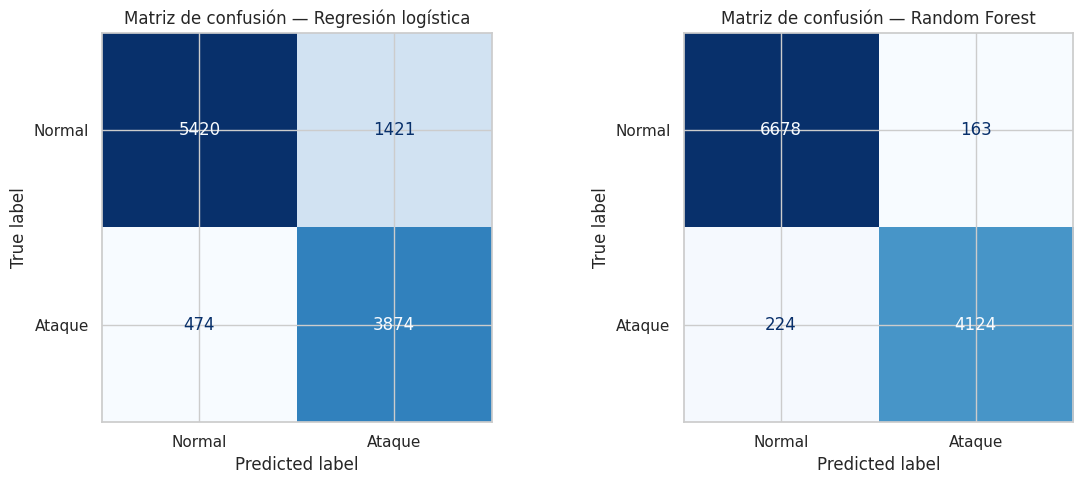

Cómo interpretarlo:
- Diagonal = aciertos (normal bien / ataque bien).
- Arriba-derecha: falsa alarma (normal marcado como ataque).
- Abajo-izquierda: falso negativo (ataque marcado como normal) → el más crítico.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, pred, titulo in [
    (axes[0], y_pred_lr, "Matriz de confusión — Regresión logística"),
    (axes[1], y_pred_rf, "Matriz de confusión — Random Forest"),
]:
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Ataque"])
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(titulo)

plt.tight_layout()
plt.savefig("img/matriz_confusion_modelos.png", dpi=150, bbox_inches="tight")
plt.show()

print("Cómo interpretarlo:")
print("- Diagonal = aciertos (normal bien / ataque bien).")
print("- Arriba-derecha: falsa alarma (normal marcado como ataque).")
print("- Abajo-izquierda: falso negativo (ataque marcado como normal) → el más crítico.")

##  Variables más importantes e interpretación

Vemos qué variables pesan más en cada modelo.  
Ya que, explica el resultado en lenguaje de negocio/seguridad, no solo con métricas.

Top variables — Random Forest:


,variable,importancia_rf
0,ct_dst_src_ltm,0.130895
1,sttl,0.101611
2,ct_state_ttl,0.084352
3,ct_srv_dst,0.058896
4,smean,0.046598
5,dload,0.046438
6,sbytes,0.046333
7,dbytes,0.033900
8,tcprtt,0.033779
9,dttl,0.033243


Top variables — Regresión logística (|coeficiente|):


,variable,coef_abs_lr,coef_lr
0,dload,16.840970,-16.840970
1,dloss,8.249073,8.249073
2,dbytes,7.629002,-7.629002
3,dttl,5.543881,5.543881
4,ct_dst_sport_ltm,3.955167,3.955167
5,swin,3.474978,-3.474978
6,dmean,3.001779,3.001779
7,sloss,2.731346,2.731346
8,ct_dst_src_ltm,1.953689,-1.953689
9,dwin,1.277789,-1.277789


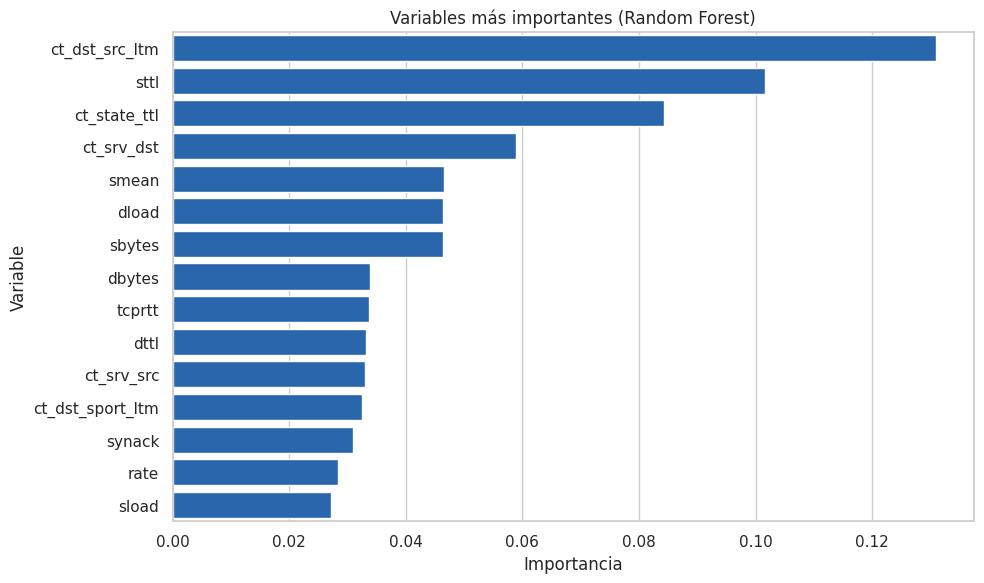


Resumen del mejor modelo según recall de ataque:
{'modelo': 'Random Forest', 'accuracy': np.float64(0.9654), 'precision_ataque': np.float64(0.962), 'recall_ataque': np.float64(0.9485), 'f1_ataque': np.float64(0.9552)}

Cómo interpretarlo:
- Variables top (p. ej. sttl, ct_*, rate, sbytes) son señales prácticas para un SOC.
- Si RF supera a logística en recall, patrones no lineales ayudan a detectar ataques.
- El modelo no 'entiende' seguridad: aprende correlaciones históricas del dataset.


In [ ]:
# Importancia en Random Forest
imp_rf = (
    pd.DataFrame({"variable": X.columns, "importancia_rf": rf.feature_importances_})
    .sort_values("importancia_rf", ascending=False)
    .head(15)
)

# Coeficientes de regresión logística (valor absoluto = fuerza de la señal)
imp_lr = (
    pd.DataFrame({
        "variable": X.columns,
        "coef_abs_lr": np.abs(log_reg.coef_[0]),
        "coef_lr": log_reg.coef_[0],
    })
    .sort_values("coef_abs_lr", ascending=False)
    .head(15)
)

print("Top variables — Random Forest:")
display(imp_rf.reset_index(drop=True))

print("Top variables — Regresión logística (|coeficiente|):")
display(imp_lr.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=imp_rf, y="variable", x="importancia_rf", color="#1565C0", ax=ax)
ax.set_title("Variables más importantes (Random Forest)")
ax.set_xlabel("Importancia")
ax.set_ylabel("Variable")
plt.tight_layout()
plt.savefig("img/importancia_variables_rf.png", dpi=150, bbox_inches="tight")
plt.show()

mejor = tabla_metricas.sort_values("recall_ataque", ascending=False).iloc[0]
print("\nResumen del mejor modelo según recall de ataque:")
print(dict(mejor))

print("\nCómo interpretarlo:")
print("- Variables top (p. ej. sttl, ct_*, rate, sbytes) son señales prácticas para un SOC.")
print("- Si RF supera a logística en recall, patrones no lineales ayudan a detectar ataques.")
print("- El modelo no 'entiende' seguridad: aprende correlaciones históricas del dataset.")

##  Aplicación profesional y conclusión

Proponemos un uso concreto en un equipo de seguridad y cerramos el proyecto.

In [ ]:
print("Aplicación profesional propuesta")
print("-" * 60)
print("Filtro de alertas para un SOC (Security Operations Center):")
print("1) El modelo puntúa cada flujo de red como probabilidad de ataque.")
print("2) Solo los casos de alta probabilidad llegan a la cola de analistas.")
print("3) Se prioriza recall alto para reducir ataques no vistos.")
print("4) Las falsas alarmas se revisan y se usan para reentrenar el modelo.")
print()
print("Conclusión")
print("-" * 60)
print("Con UNSW-NB15 demostramos que la ciencia de datos puede identificar")
print("patrones asociados a amenazas y anticipar tráfico sospechoso.")
print("La estadística reveló diferencias entre normal y malicioso; el modelo")
print("convirtió esas señales en predicciones evaluables (accuracy y recall).")
print("El siguiente paso profesional sería validar con tráfico propio de la")
print("organización y combinar el modelo con reglas de negocio del equipo de seguridad.")

Aplicación profesional propuesta
------------------------------------------------------------
Filtro de alertas para un SOC (Security Operations Center):
1) El modelo puntúa cada flujo de red como probabilidad de ataque.
2) Solo los casos de alta probabilidad llegan a la cola de analistas.
3) Se prioriza recall alto para reducir ataques no vistos.
4) Las falsas alarmas se revisan y se usan para reentrenar el modelo.

Conclusión
------------------------------------------------------------
Con UNSW-NB15 demostramos que la ciencia de datos puede identificar
patrones asociados a amenazas y anticipar tráfico sospechoso.
La estadística reveló diferencias entre normal y malicioso; el modelo
convirtió esas señales en predicciones evaluables (accuracy y recall).
El siguiente paso profesional sería validar con tráfico propio de la
organización y combinar el modelo con reglas de negocio del equipo de seguridad.
